# Lab 01 - EDA (FashionMNIST)

Notebook này thực thi bước **Exploratory Data Analysis** theo `docs/eda-image.md`.
Toàn bộ phép tính nằm trong `src/eda.py`; notebook chỉ gọi hàm và hiển thị kết quả.

Mục tiêu: tạo stratified split **một lần**, đo các thống kê cần thiết, và ghi
artifact để notebook Feature Engineering đọc lại. Không quyết định gì về mô hình
ở bước này.

## E0. Thiết lập môi trường

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DATA_DIR, EDA_DIR, CLASS_NAMES, RANDOM_SEED, FALLBACK_STD,
    VAL_SPLIT, SPLIT_VERSION, NUM_CLASSES,
)
from src.split import make_stratified_split, save_split, load_split_metadata
from src import eda as eda_mod
from src.eda import FOREGROUND_THRESHOLD
from src.utils import set_seed

TABLES_DIR = EDA_DIR / "tables"
FIGURES_DIR = EDA_DIR / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

set_seed(RANDOM_SEED)
print(f"[EDA_DIR] {EDA_DIR}")
print(f"[SPLIT_VERSION] {SPLIT_VERSION} | [FOREGROUND_THRESHOLD] {FOREGROUND_THRESHOLD}")

[EDA_DIR] C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda
[SPLIT_VERSION] split_v2_stratified | [FOREGROUND_THRESHOLD] 0.1


## E1. Nạp dữ liệu thô và tạo split một lần

Split được lưu thành artifact. Mọi bước sau đọc lại artifact này, không chia lại.
Ba assert dưới đây chặn ba lỗi split phổ biến: chồng lấn, thiếu phủ, và validation
lệch lớp.

In [2]:
X_pool, y_pool, X_test_raw, y_test_raw = eda_mod.load_raw_arrays(DATA_DIR)
print(f"[RAW] pool={X_pool.shape} test={X_test_raw.shape} dtype={X_pool.dtype}")

train_idx, val_idx = make_stratified_split(
    y_pool, val_split=VAL_SPLIT, seed=RANDOM_SEED
)
npz_path = save_split(
    out_dir=EDA_DIR, train_idx=train_idx, val_idx=val_idx, targets=y_pool,
    seed=RANDOM_SEED, val_split=VAL_SPLIT, version=SPLIT_VERSION,
    extra={"foreground_threshold": FOREGROUND_THRESHOLD},
)
split_meta = load_split_metadata(EDA_DIR)

assert np.intersect1d(train_idx, val_idx).size == 0, "train/val indices overlap"
assert len(train_idx) + len(val_idx) == len(y_pool), "split does not cover the pool"
assert min(split_meta["val_class_counts"]) == max(split_meta["val_class_counts"]), \
    "validation partition is not class-balanced"

X_tr, y_tr = X_pool[train_idx], y_pool[train_idx]
X_va, y_va = X_pool[val_idx], y_pool[val_idx]
print(f"[SPLIT] version={split_meta['split_version']} seed={split_meta['seed']}")
print(f"[SPLIT] train={split_meta['train_size']} val={split_meta['val_size']}")
print(f"[ARTIFACT] {npz_path}")

[RAW] pool=(60000, 28, 28) test=(10000, 28, 28) dtype=uint8


[SPLIT] version=split_v2_stratified seed=42
[SPLIT] train=54000 val=6000
[ARTIFACT] C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\split_indices.npz


## E2. Step 1 - Tổng quan cấu trúc

Kiểm tra shape, dtype, số kênh, khoảng pixel và bộ nhớ. Đây là bước rẻ nhất và
phát hiện được nhiều lỗi nạp dữ liệu trước khi tốn công phân tích sâu.

In [3]:
overview = eda_mod.structural_overview(
    X_pool, y_pool, X_test_raw, y_test_raw, CLASS_NAMES
)
overview.to_csv(TABLES_DIR / "structural_overview.csv", index=False)
display(overview)

,partition,num_images,image_height,image_width,num_channels,array_shape,dtype,pixel_min,pixel_max,num_labels,label_min,label_max,num_classes_present,num_class_names_defined,memory_MB
0,original_train,60000,28,28,1,"(60000, 28, 28)",uint8,0,255,60000,0,9,10,10,44.861
1,original_test,10000,28,28,1,"(10000, 28, 28)",uint8,0,255,10000,0,9,10,10,7.477
2,summary,70000,28,28,1,n/a,uint8,0,255,70000,0,9,10,10,52.338


## E3. Step 2 - Kiểm tra tính toàn vẹn

Ba phép kiểm tra khác nhau và phải báo riêng: label ngoài miền, pixel ngoài miền,
và ảnh trùng lặp. Trùng lặp trong một split khác với trùng lặp giữa các split.

Không xóa ảnh nào ở bước này. Ảnh nghi vấn chỉ được ghi lại để xem xét.

In [4]:
integrity_summary, integrity_details = eda_mod.integrity_report(
    X_pool, y_pool, X_test_raw, y_test_raw, train_idx, val_idx, NUM_CLASSES
)
integrity_summary.to_csv(TABLES_DIR / "integrity_report.csv", index=False)
display(integrity_summary)

,check,expected,num_flagged,detail_file
0,labels_in_range,"[0, 9]",0.0,"invalid_train_labels, invalid_test_labels"
1,pixel_range_0_255,"all pixels within [0, 255]",0.0,n/a
2,nan_or_inf_pixels,0 (uint8 storage cannot represent NaN/Inf),0.0,n/a
3,all_black_images,0 images with maximum pixel 0,0.0,"all_black_train, all_black_test"
4,split_indices_disjoint,0 overlapping indices,0.0,n/a
5,split_coverage,60000 samples covered exactly once,0.0,n/a
6,exact_duplicate_within_train,0 duplicated images (content hash),0.0,exact_duplicate_train
7,exact_duplicate_train_vs_test,0 identical images across partitions,0.0,exact_duplicate_train_test
8,near_duplicates,not implemented (out of scope; see walkthrough...,NaN,n/a


## E4. Step 3 - Phân phối lớp

Không mặc định phân phối cân bằng; tính từ dữ liệu. Bảng của test chỉ lập sau khi
khóa cấu hình, nên ở đây chỉ so sánh train với validation.

In [5]:
distribution = eda_mod.class_distribution(y_tr, y_va, CLASS_NAMES)
distribution.to_csv(TABLES_DIR / "class_distribution.csv", index=False)
display(distribution)

train_counts = np.bincount(y_tr, minlength=NUM_CLASSES)
val_counts = np.bincount(y_va, minlength=NUM_CLASSES)
print(f"[TRAIN] min={train_counts.min()} max={train_counts.max()}")
print(f"[VAL]   min={val_counts.min()} max={val_counts.max()}")

,split,label,class_name,count,percent,split_total
0,train,0,T-shirt/top,5400,10.0,54000
1,train,1,Trouser,5400,10.0,54000
2,train,2,Pullover,5400,10.0,54000
3,train,3,Dress,5400,10.0,54000
4,train,4,Coat,5400,10.0,54000
5,train,5,Sandal,5400,10.0,54000
6,train,6,Shirt,5400,10.0,54000
7,train,7,Sneaker,5400,10.0,54000
8,train,8,Bag,5400,10.0,54000
9,train,9,Ankle boot,5400,10.0,54000


[TRAIN] min=5400 max=5400
[VAL]   min=600 max=600


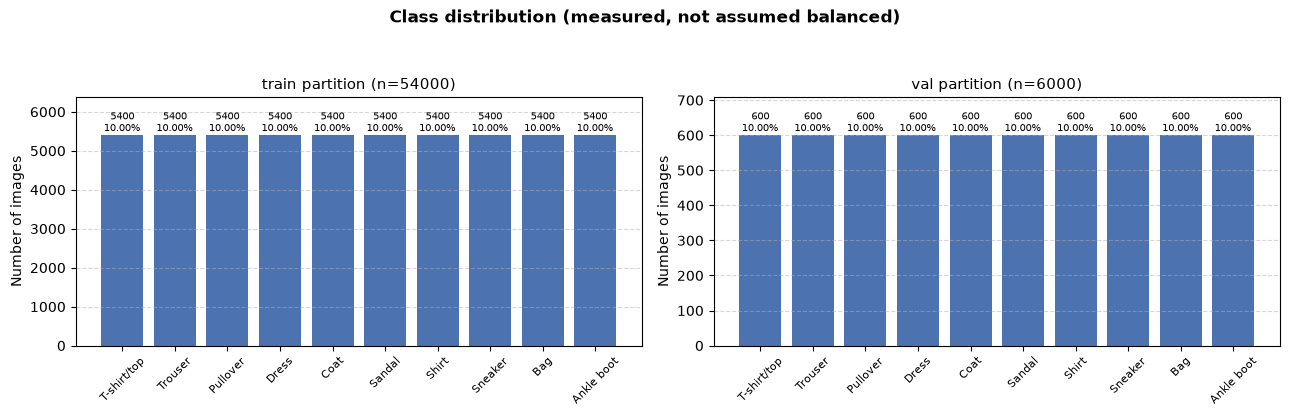

In [6]:
fig = eda_mod.plot_class_distribution(
    distribution, save_path=FIGURES_DIR / "class_distribution.png"
)
plt.show()

## E5. Step 4 - Kiểm tra trực quan

Chọn mẫu bằng random seed, không lấy những ảnh đầu tiên. Mean image theo lớp
**làm mất phương sai trong lớp**: hai lớp có mean gần giống nhau vẫn có thể phân
biệt hoàn hảo, nên mean image chỉ tạo giả thuyết.

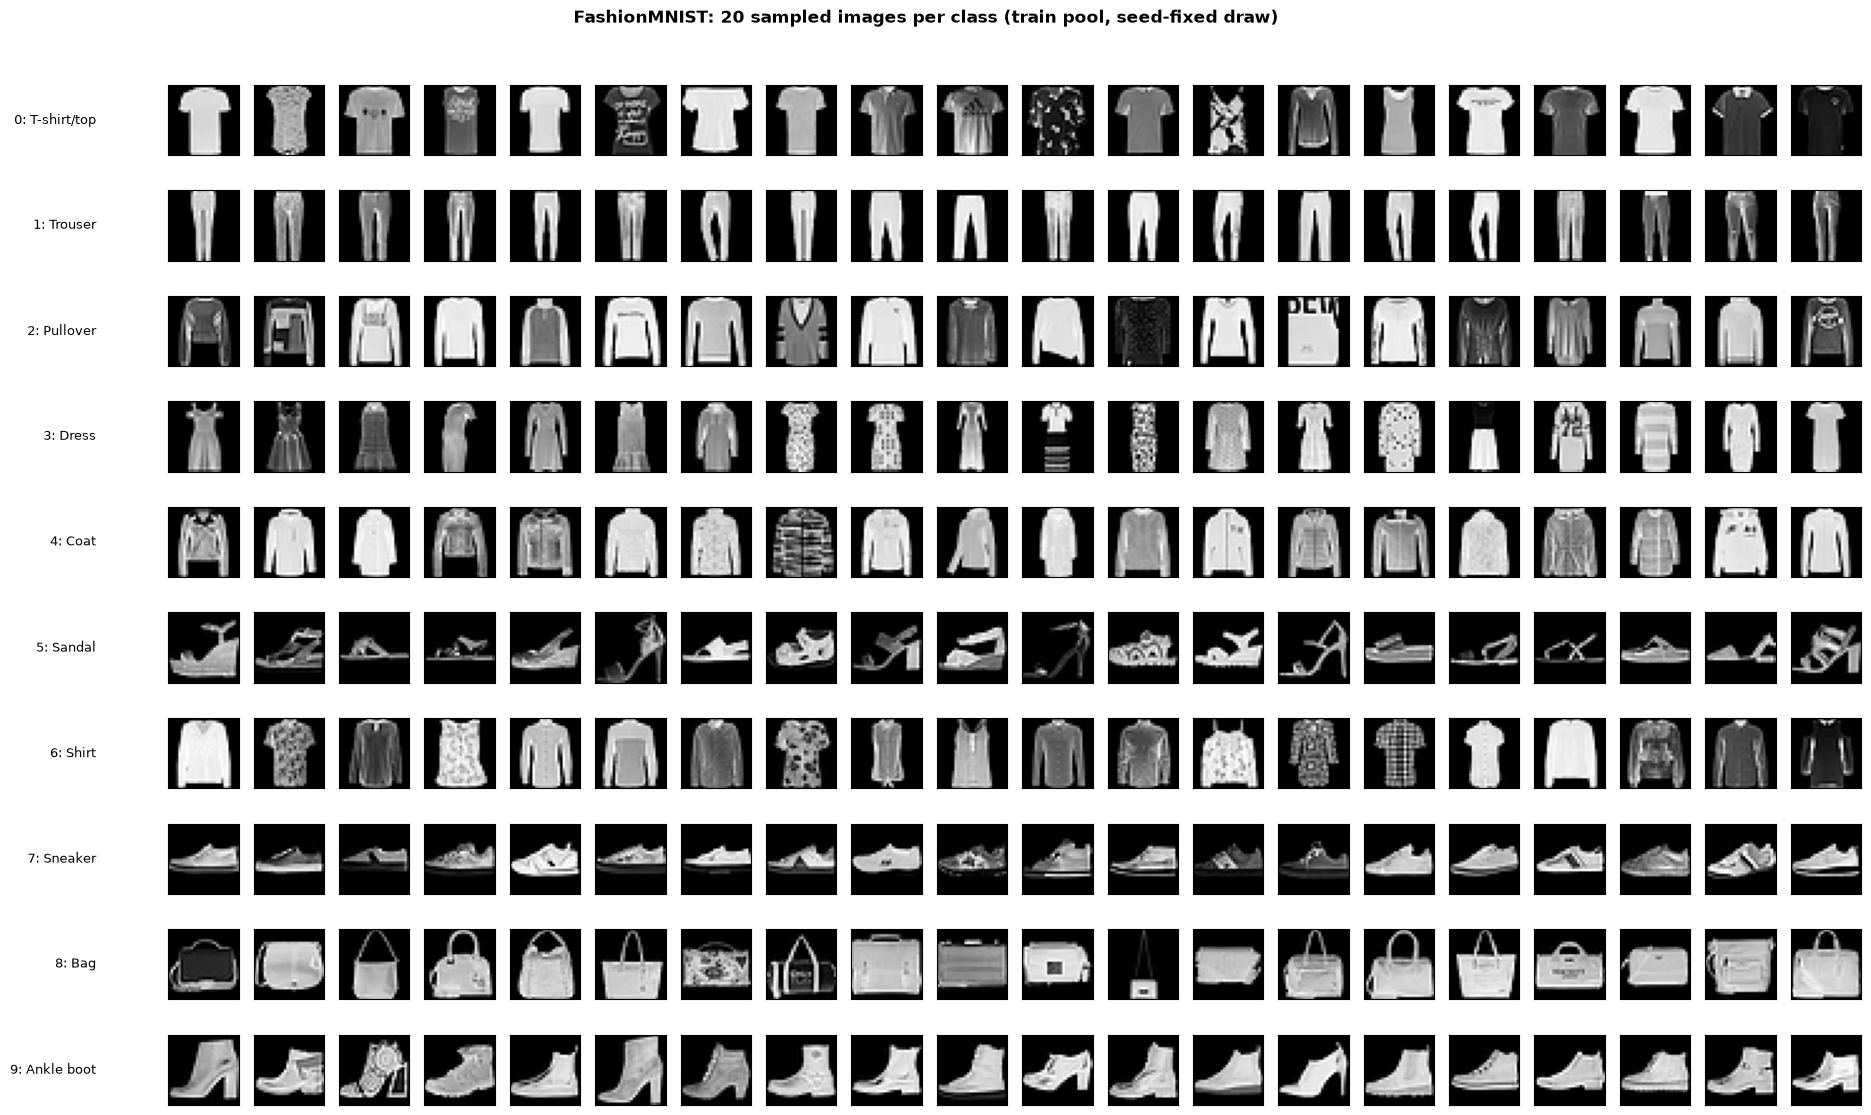

In [7]:
picks = eda_mod.sample_images_per_class(
    X_tr, y_tr, CLASS_NAMES, n_per_class=20, seed=RANDOM_SEED
)
fig = eda_mod.plot_sample_grid(
    X_tr, picks, y_tr, CLASS_NAMES, save_path=FIGURES_DIR / "sample_images.png"
)
plt.show()

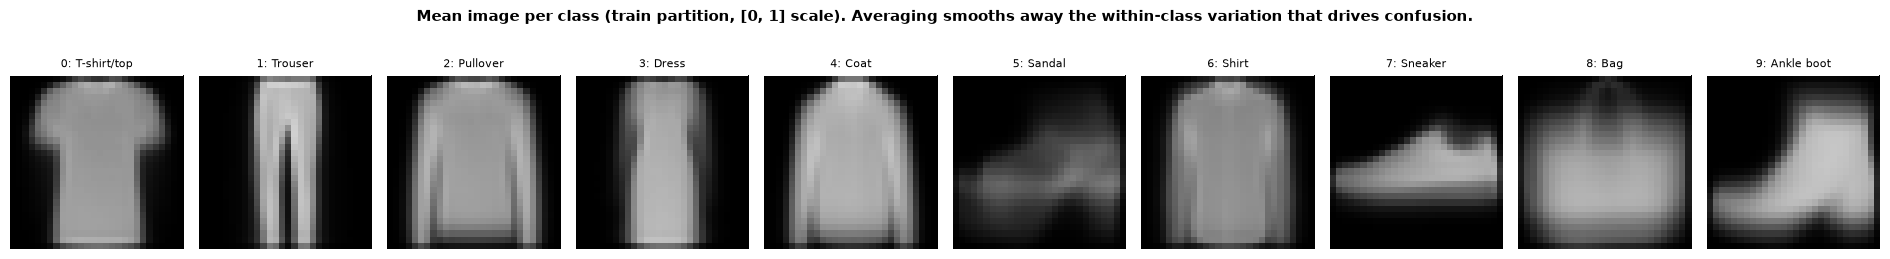

In [8]:
mean_images = eda_mod.class_mean_images(X_tr, y_tr, CLASS_NAMES)
np.save(EDA_DIR / "class_mean_images.npy", mean_images)

fig = eda_mod.plot_class_mean_images(
    mean_images, CLASS_NAMES, save_path=FIGURES_DIR / "class_mean_images.png"
)
plt.show()

## E6. Step 5 - Thống kê cường độ pixel

Đo trên **scaled view** `[0, 1]` của train, trước augmentation, không `drop_last`.
`std(ddof=0)` là population variance, khớp với giả định của
`torchvision.transforms.Normalize`.

Cột `per_image_std_mean` là đại lượng **khác** với global std: nó bỏ qua phương
sai giữa các ảnh nên luôn nhỏ hơn. Không dùng nó làm mẫu số.

In [9]:
train_stats = eda_mod.compute_normalization_stats(X_tr)
pd.DataFrame([train_stats]).to_csv(
    TABLES_DIR / "normalization_stats_measurement.csv", index=False
)
print(json.dumps({k: round(v, 6) for k, v in train_stats.items()}, indent=2))

{
  "mean": 0.286209,
  "std": 0.35316,
  "num_images": 54000,
  "num_pixels": 42336000,
  "per_image_std_mean": 0.320661,
  "per_image_std_ddof0_mean": 0.320456,
  "per_image_mean_mean": 0.286209,
  "zero_pixel_fraction": 0.502143
}


In [10]:
pixel_by_class = eda_mod.pixel_statistics_by_class(X_tr, y_tr, CLASS_NAMES)
pixel_by_class.to_csv(TABLES_DIR / "pixel_statistics.csv", index=False)
display(pixel_by_class)

,label,class_name,count,pixel_mean,pixel_std,zero_pixel_fraction,image_brightness_mean,image_brightness_std,image_brightness_min,image_brightness_max
0,0,T-shirt/top,5400,0.325581,0.350651,0.406169,0.325581,0.113085,0.038250,0.682273
1,1,Trouser,5400,0.223160,0.343632,0.650929,0.223159,0.057078,0.059329,0.697059
2,2,Pullover,5400,0.377130,0.359160,0.351639,0.377130,0.128223,0.051671,0.740041
3,3,Dress,5400,0.258485,0.354167,0.573341,0.258485,0.083648,0.038570,0.559224
4,4,Coat,5400,0.384889,0.376076,0.398063,0.384889,0.103778,0.043487,0.698624
5,5,Sandal,5400,0.136754,0.263097,0.678988,0.136754,0.061717,0.019388,0.437515
6,6,Shirt,5400,0.332703,0.339943,0.371335,0.332703,0.129023,0.039201,0.752236
7,7,Sneaker,5400,0.167892,0.294946,0.661893,0.167892,0.050384,0.040591,0.463986
8,8,Bag,5400,0.354044,0.365415,0.413867,0.354044,0.112973,0.047824,0.725795
9,9,Ankle boot,5400,0.301452,0.370652,0.515206,0.301452,0.071857,0.060579,0.562715


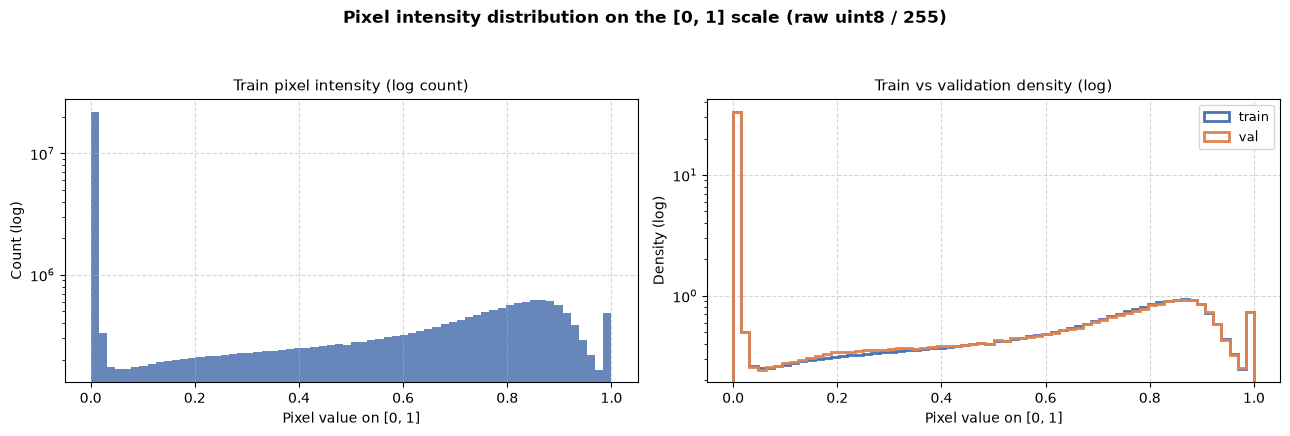

In [11]:
fig = eda_mod.plot_pixel_histogram(
    X_tr, X_va, save_path=FIGURES_DIR / "pixel_histogram.png"
)
plt.show()

## E7. Step 6 - Phân tích không gian

Tính mean map, variance map, tần suất pixel bằng 0, foreground ratio và bounding
box theo lớp.

Foreground dùng ngưỡng có tên (`FOREGROUND_THRESHOLD`), không dùng `pixel != 0`:
với ảnh có nền lớn, ngưỡng 0 sẽ gộp nhiễu nền vào bounding box và làm mọi aspect
ratio vô nghĩa.

In [12]:
spatial = eda_mod.spatial_features(
    X_tr, y_tr, CLASS_NAMES, threshold=FOREGROUND_THRESHOLD
)
spatial.to_csv(TABLES_DIR / "spatial_features.csv", index=False)
print(spatial.groupby("class_name")[["foreground_ratio", "bbox_aspect_ratio"]].mean())

             foreground_ratio  bbox_aspect_ratio
class_name                                      
Ankle boot           0.435545           1.358522
Bag                  0.535816           1.174043
Coat                 0.565029           0.723940
Dress                0.391501           0.525002
Pullover             0.607485           0.763638
Sandal               0.252617           2.032288
Shirt                0.577219           0.777170
Sneaker              0.287219           2.149875
T-shirt/top          0.532581           0.785042
Trouser              0.331041           0.418274


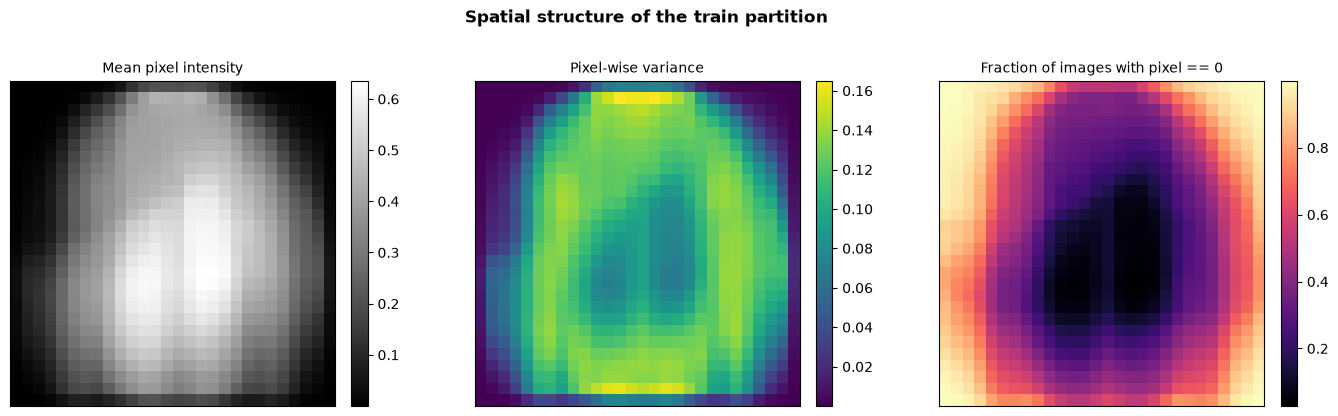

In [13]:
fig = eda_mod.plot_heatmaps(
    eda_mod.mean_pixel_map(X_tr),
    eda_mod.pixel_variance_map(X_tr),
    eda_mod.zero_pixel_frequency_map(X_tr),
    save_path=FIGURES_DIR / "spatial_heatmaps.png",
)
plt.show()

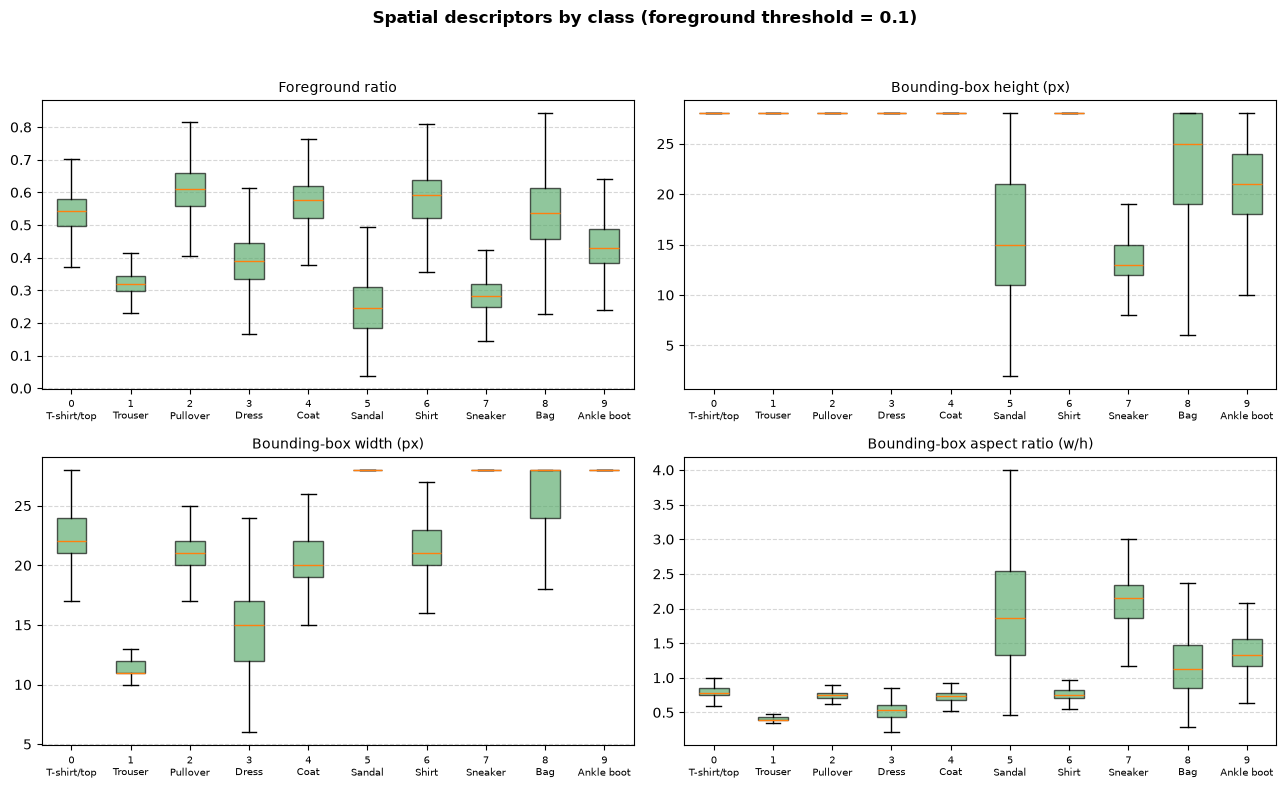

In [14]:
fig = eda_mod.plot_spatial_by_class(
    spatial, CLASS_NAMES, save_path=FIGURES_DIR / "spatial_by_class.png"
)
plt.show()

## E8. Step 8 - Tương đồng giữa các lớp

Cosine và correlation giữa mean image của các lớp. Đây là **máy tạo giả thuyết**,
không phải kết luận. Xác nhận phải bằng confusion matrix và per-class metric sau
khi huấn luyện.

In [15]:
cosine_sim = eda_mod.class_similarity_matrix(mean_images, CLASS_NAMES, metric="cosine")
corr_sim = eda_mod.class_similarity_matrix(
    mean_images, CLASS_NAMES, metric="correlation"
)
cosine_sim.to_csv(TABLES_DIR / "class_similarity_matrix.csv")
corr_sim.to_csv(TABLES_DIR / "class_correlation_matrix.csv")

top_cosine = eda_mod.most_similar_pairs(cosine_sim, top_k=12)
top_corr = eda_mod.most_similar_pairs(corr_sim, top_k=12)
top_cosine.to_csv(TABLES_DIR / "most_similar_pairs_cosine.csv", index=False)
top_corr.to_csv(TABLES_DIR / "most_similar_pairs_correlation.csv", index=False)

print("[TOP 5 - COSINE]")
display(top_cosine.head())

[TOP 5 - COSINE]


,class_a,class_b,similarity
0,Coat,Shirt,0.987286
1,Pullover,Coat,0.984075
2,Pullover,Shirt,0.982976
3,T-shirt/top,Shirt,0.949727
4,Sandal,Ankle boot,0.926082


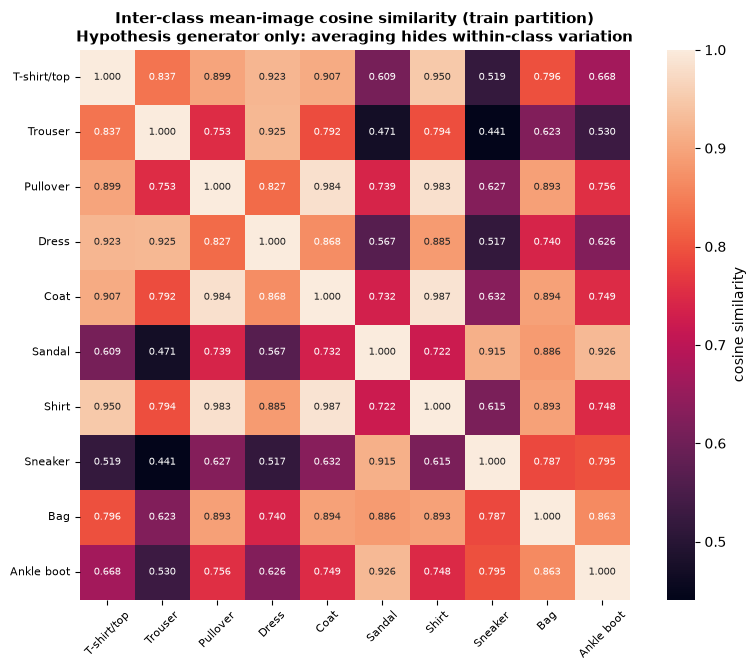

In [16]:
fig = eda_mod.plot_similarity_heatmap(
    cosine_sim, "cosine", save_path=FIGURES_DIR / "class_similarity_heatmap.png"
)
plt.show()

## E9. Step 13 - Tổng hợp phát hiện

Gom mọi con số **đã đo** vào một file JSON. Nhận xét trong walkthrough chỉ được
trích từ file này, nên không thể lệch khỏi artifact.

In [17]:
findings = eda_mod.build_findings(
    split_meta=split_meta,
    train_stats=train_stats,
    spatial=spatial,
    integrity_summary=integrity_summary,
    top_cosine=top_cosine,
    top_correlation=top_corr,
    legacy_std=float(FALLBACK_STD[0]),
    foreground_threshold=FOREGROUND_THRESHOLD,
    test_size=len(y_test_raw),
)
with open(EDA_DIR / "eda_findings.json", "w", encoding="utf-8") as f:
    json.dump(findings, f, indent=2)
print(json.dumps(findings, indent=2))

{
  "split_version": "split_v2_stratified",
  "train_size": 54000,
  "val_size": 6000,
  "test_size_held_out": 10000,
  "train_class_count_min": 5400,
  "train_class_count_max": 5400,
  "val_class_count_min": 600,
  "val_class_count_max": 600,
  "train_pixel_mean": 0.286209,
  "train_pixel_std_ddof0": 0.35316,
  "train_per_image_std_mean": 0.320661,
  "legacy_config_std": 0.3205,
  "zero_pixel_fraction_train": 0.502143,
  "foreground_threshold": 0.1,
  "foreground_ratio_mean": 0.451605,
  "empty_foreground_images": 0,
  "exact_duplicate_within_train": 0,
  "exact_duplicate_train_vs_test": 0,
  "all_black_images": 0,
  "top_similar_pair_cosine": "Coat / Shirt = 0.9873",
  "top_similar_pair_correlation": "Coat / Shirt = 0.9666"
}


In [18]:
handoff = eda_mod.build_handoff_table(findings, train_stats)
handoff.to_csv(TABLES_DIR / "eda_to_fe_handoff.csv", index=False)
display(handoff[["finding", "status"]])

,finding,status
0,"Split stratified 54,000/6,000, moi lop 5,400/600",measured
1,"Global train pixel mean=0.286209, std(ddof=0)=...",measured
2,"Config cu dung std=0.3205, bang mean cua per-i...",measured
3,Khong co exact duplicate trong train pool va k...,measured
4,Pixel 0 chiem 0.5021 tong pixel,measured
5,Cap lop giong nhau nhat (cosine): Coat / Shirt...,hypothesis
6,Handcrafted features (Step 7),not_run
7,PCA / t-SNE (Step 9),not_run
8,Outlier scoring (Step 10),not_run
9,Distribution shift train/val (Step 11),not_run


## E10. Bàn giao

Bảng handoff phân loại mỗi phát hiện thành ba trạng thái: `measured` (đã đo),
`hypothesis` (cần confusion matrix xác nhận), và `not_run` (chủ động bỏ, có lý do).

Các bước chưa chạy: handcrafted features (Step 7), PCA/t-SNE (Step 9), outlier
scoring (Step 10), distribution shift (Step 11), baseline LR/kNN (Step 12). Lý do
ghi trong cột `proposal` của bảng handoff.

In [19]:
for path in sorted(EDA_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(EDA_DIR)}  ({path.stat().st_size:,} bytes)")

class_mean_images.npy  (31,488 bytes)
eda_findings.json  (759 bytes)
feature_engineering_summary.json  (351 bytes)
figures\augmentation_examples.png  (518,872 bytes)
figures\augmentation_preview.png  (61,606 bytes)
figures\class_distribution.png  (101,799 bytes)
figures\class_mean_images.png  (57,797 bytes)
figures\class_similarity_heatmap.png  (204,147 bytes)
figures\image_brightness_distribution.png  (78,200 bytes)
figures\pixel_histogram.png  (79,935 bytes)
figures\sample_images.png  (350,353 bytes)
figures\spatial_by_class.png  (142,132 bytes)
figures\spatial_heatmaps.png  (69,612 bytes)
preprocessing_config.json  (359 bytes)
spatial_maps.npz  (11,640 bytes)
split_indices.npz  (91,754 bytes)
split_metadata.json  (718 bytes)
tables\class_correlation_matrix.csv  (1,991 bytes)
tables\class_distribution.csv  (662 bytes)
tables\class_similarity_matrix.csv  (2,015 bytes)
tables\data_cleaning_log.csv  (176 bytes)
tables\data_review.csv  (441 bytes)
tables\eda_to_fe_handoff.csv  (2,122 byt